## Задание 3

### 3.1

#### Микро-подход

Cтроки матрицы можно расположить одну за другой, чтобы получился один длинный вектор. Такую операцию проделываем с матрицей истинных ответов и матрицей предсказаний, получая набор из $N$ вопросов вида "принадлежит ли объект $i$ к классу $j$", что сводит задачу к бинарной.

У нас $4$ объекта ($m=4$) и $3$ класса ($l=3$). Всего решений: $4 \cdot 3 = 12$.

Выпишем каждую ячейку $(i, j)$ как отдельное наблюдение:

| Объект | Класс | Истина ($Y$) | Оценка модели ($A$) |
| :---: | :---: | :---: | :---: |
| 0 | 1 | 1 | 0.7 |
| 0 | 2 | 1 | 0.6 |
| 0 | 3 | 0 | 0.5 |
| 1 | 1 | 0 | 0.3 |
| 1 | 2 | 1 | 0.4 |
| 1 | 3 | 1 | 0.6 |
| 2 | 1 | 0 | 0.5 |
| 2 | 2 | 1 | 0.9 |
| 2 | 3 | 0 | 0.2 |
| 3 | 1 | 1 | 0.4 |
| 3 | 2 | 0 | 0.5 |
| 3 | 3 | 0 | 0.1 |

Теперь посчитать AUC можно по формуле:

$$\text{AUC} = \frac{\sum_{i=1}^m \sum_{j=1}^m I[y_i < y_j] \cdot I[a_i < a_j]}{\sum_{i=1}^m \sum_{j=1}^m I[y_i < y_j]}$$

Выражение $I[y_i < y_j]$ равно $1$ только тогда, когда $y_i = 0$, а $y_j = 1$, то есть, мы смотрим только на пары $(0, 1)$. Выражение $\sum_{i=1}^m \sum_{j=1}^m I[y_i < y_j] \cdot I[a_i < a_j]$ таким образом используется для подсчёта, сколько было случаев, когда оценки модели были выданы правильно.

В нашем случае имеется $6$ истинных единиц и $6$ истинных нулей.

* Оценки для единиц ($S_+$):  
  $[0.9, 0.7, 0.6, 0.6, 0.4, 0.4]$
* Оценки для нулей ($S_-$):  
  $[0.5, 0.5, 0.5, 0.3, 0.2, 0.1]$

Всего можно составить $6 \cdot 6 = 36$ пар вида (оценка нуля, оценка единицы).  
Модель права, если оценка единицы строго выше оценки нуля (дает $+1$ к сумме, а если оценки равны, то $+0.5$).

Сравним каждую единицу со всеми шестью нулями:
1. $0.9$ больше, чем все нули: $0.5, 0.5, 0.5, 0.3, 0.2, 0.1$ $\implies +6$.
2. $0.7$ больше, чем все нули $\implies +6$.
3. Первая $0.6$ больше, чем все нули $\implies +6$.
4. Вторая $0.6$ больше, чем все нули $\implies +6$.
5. Первая $0.4$ больше нулей $0.3, 0.2, 0.1$, но меньше трех $0.5$ $\implies +3$.
6. Вторая $0.4$ больше нулей $0.3, 0.2, 0.1$ $\implies +3$.

Итоговую сумму делим на общее число пар:
$$\text{micro} = \frac{6 + 6 + 6 + 6 + 3 + 3}{36} = \frac{5}{6} \approx 0.833$$

Именно это число $0.833$ и будет значением **micro**.

#### Макро-подход

Смотрим на матрицы по столбцам и оцениваем каждый класс независимо от других, в конце находим AUC как среднее арифметическое.

Когда мы берём только один столбец, то снова получаем бинарную задачу. AUC здесь считается по той же формуле, что и в микро-подходе.

* class 1 (столбец 1):
  * Истиные ответы: $Y = [1, 0, 0, 1]$. Оценки для единиц: $[0.7, 0.4]$. Оценки для нулей: $[0.3, 0.5]$.
  * Сравниваем 4 пары (каждую единицу со всеми нулями):
    * $0.7 > 0.3 \implies +1$
    * $0.7 > 0.5 \implies +1$
    * $0.4 > 0.3 \implies +1$
    * $0.4 < 0.5 \implies +0$
  * Угадано $3$ из $4$ пар $\implies \text{AUC}_{\text{class 1}} = 3/4 = 0.75$.
* class 2 (столбец 2):
  * Оценки для единиц: $[0.6, 0.4, 0.9]$. Оценки для нулей: $[0.5]$.
  * Из $3$ пар модель угадала $2$: $0.6 > 0.5$ и $0.9 > 0.5$, но $0.4 < 0.5$.
  * $\text{AUC}_{\text{class 2}} = 2/3 \approx 0.667$.
* class 3 (столбец 3):
  * Оценки для единиц: $[0.6]$. Оценки для нулей: $[0.5, 0.2, 0.1]$.
  * $0.6$ больше всех отрицательных, угадано $3$ из $3$ пар.
  * $\text{AUC}_{\text{class 3}} = 3/3 = 1.0$.

Среднее арифметическое трёх чисел:
$$\text{macro} = \frac{0.750 + 0.667 + 1.000}{3} \approx 0.806$$

Таким образом, значением **macro** будет число $0.806$.

Можно заметить, что каждое промежуточное значение учитывается в равной степени, поэтому если модель плохо распознаёт один конкретный класс, даже если он очень маленький, это может ощутимо занизить итоговую метрику.

#### Взвешенный подход

Похож на макро-подход: считаем по столбцам, но в конце вместо нахождения среднего арифметического домножаем каждое значение на свой вес, где весами выступают частоты встречаемости классов.

AUC для каждого столбца посчитан на предыдущем шаге. Рассчитаем веса:

* Всего единиц в матрице: $2 + 3 + 1 = 6$.
* В первом классе 2 единицы из 4 объектов $\implies 2/6 = 1/3$
* Во втором классе 3 единицы из 4 $\implies 3/6 = 1/2$
* В третьем классе 1 единица из 4 $\implies 1/6$

Теперь домножим значения на веса и найдём сумму:
$$\text{weighted} = \frac{1}{3} \times 0.750 + \frac{1}{2} \times 0.667 + \frac{1}{6} \times 1.000 = 0.25 + 0.333 + 0.167 = 0.75$$

Число $0.75$ будет значением **weighted**.

#### Пообъектный подход

Смотрим на матрицы по строкам и оцениваем, насколько правильно модель расставила приоритеты для каждого конкретного объекта.

Одна строка это снова бинарная задача, для которой считаем AUC, и в конце находим среднее арифметическое.

* **Объект 1 (строка 0):** Оценки для единиц: $[0.7, 0.6]$, оценки для нулей: $[0.5]$.
  * $0.7 > 0.5$ и $0.6 > 0.5$. Все $2$ пары верны $\implies x_1 = 1.0$.
* **Объект 2 (строка 1):** Оценки для единиц: $[0.4, 0.6]$, оценки для нулей: $[0.3]$.
  * $0.4 > 0.3$ и $0.6 > 0.3$. Все верно $\implies x_2 = 1.0$.
* **Объект 3 (строка 2):** Оценки для единиц: $[0.9]$, оценки для нулей: $[0.5, 0.2]$.
  * $0.9 > 0.5$ и $0.9 > 0.2$. Все верно $\implies x_3 = 1.0$.
* **Объект 4 (строка 3):** Оценки для единиц: $[0.4]$, оценки для нулей: $[0.5, 0.1]$.
  * $0.4 > 0.1$, но $0.4 < 0.5$. Угадана $1$ пара из $2$ $\implies x_4 = 1/2 = 0.5$.

Cреднее по всем $4$ объектам:
$$\text{samples} = \frac{1.0 + 1.0 + 1.0 + 0.5}{4} = \frac{3.5}{4} = 0.875$$

Таким образом, **samples** будет равен $0.875$.

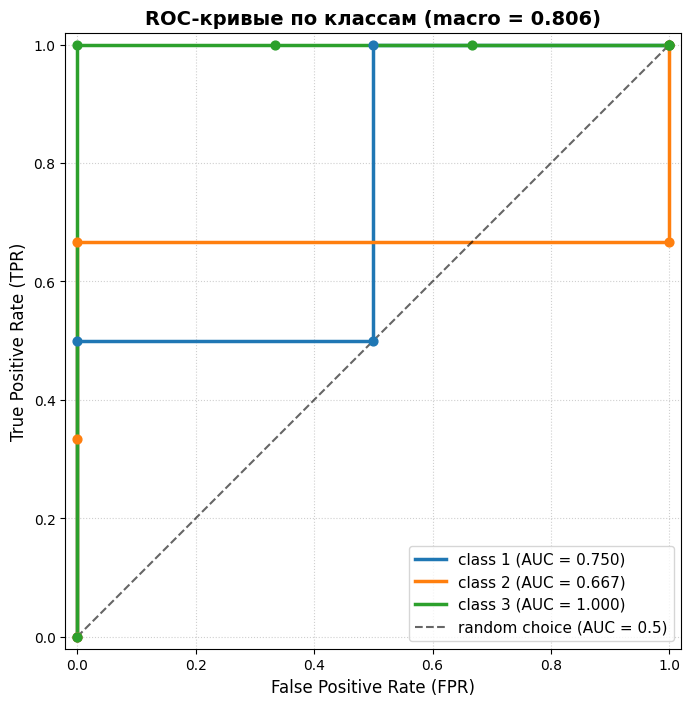

Class 1 AUC: 0.750
Class 2 AUC: 0.667
Class 3 AUC: 1.000
Macro AUC:   0.806


In [4]:
# визуализация ROC для макро-подхода

import matplotlib.pyplot as plt
import numpy as np

Y = np.array([[1, 1, 0], [0, 1, 1], [0, 1, 0], [1, 0, 0]])

A = np.array([[0.7, 0.6, 0.5], [0.3, 0.4, 0.6], [0.5, 0.9, 0.2], [0.4, 0.5, 0.1]])

class_names = ["class 1", "class 2", "class 3"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]


def compute_roc_curve(y_true_col, scores_col):
    thresholds = np.sort(np.unique(scores_col))[::-1]
    thresholds = np.concatenate([[thresholds[0] + 1e-5], thresholds, [0.0]])

    fprs, tprs = [], []
    pos_count = np.sum(y_true_col == 1)
    neg_count = np.sum(y_true_col == 0)

    for t in thresholds:
        preds = (scores_col >= t).astype(int)
        tp = np.sum((preds == 1) & (y_true_col == 1))
        fp = np.sum((preds == 1) & (y_true_col == 0))

        fprs.append(fp / neg_count)
        tprs.append(tp / pos_count)

    fprs = np.array(fprs)
    tprs = np.array(tprs)

    auc = 0.0
    for i in range(len(fprs) - 1):
        auc += (fprs[i + 1] - fprs[i]) * (tprs[i + 1] + tprs[i]) / 2.0

    return fprs, tprs, auc


plt.figure(figsize=(8, 8))

auc_scores = []

for col_idx in range(Y.shape[1]):
    y_col = Y[:, col_idx]
    score_col = A[:, col_idx]

    fpr, tpr, auc = compute_roc_curve(y_col, score_col)
    auc_scores.append(auc)

    plt.plot(
        fpr,
        tpr,
        color=colors[col_idx],
        lw=2.5,
        label=f"{class_names[col_idx]} (AUC = {auc:.3f})",
        drawstyle="default",
    )
    plt.scatter(fpr, tpr, color=colors[col_idx], s=40, zorder=4)

macro_auc = np.mean(auc_scores)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    lw=1.5,
    alpha=0.6,
    label="random choice (AUC = 0.5)",
)

plt.title(
    f"ROC-кривые по классам (macro = {macro_auc:.3f})",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("False Positive Rate (FPR)", fontsize=12)
plt.ylabel("True Positive Rate (TPR)", fontsize=12)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", fontsize=11)
plt.gca().set_aspect("equal", adjustable="box")

plt.show()

print(f"Class 1 AUC: {auc_scores[0]:.3f}")
print(f"Class 2 AUC: {auc_scores[1]:.3f}")
print(f"Class 3 AUC: {auc_scores[2]:.3f}")
print(f"Macro AUC:   {macro_auc:.3f}")

### 3.2

#### Данные по class 1 и три порога

Берём данные для **class 1** (столбец $1$):
* Объект 0: Истина $y = 1$, оценка $a = 0.7$
* Объект 1: Истина $y = 0$, оценка $a = 0.3$
* Объект 2: Истина $y = 0$, оценка $a = 0.5$
* Объект 3: Истина $y = 1$, оценка $a = 0.4$

Всего реальных единиц: $2$ (объекты $0$ и $3$). Всего нулей: $2$ (объекты $1$ и $2$).

Формулы:
* $\text{Accuracy} = \frac{TP + TN}{TN + FN + TP + FP}$
* $\text{Precision} = \frac{TP}{TP + FP}$
* $\text{Recall} = \frac{TP}{TP + FN}$

#### Порог 1: $T = 0.60$
Модель ставит $1$, только если оценка $\ge 0.60$.
* Предсказания: объект 0 $\to 1$; объекты 1, 2, 3 $\to 0$.
* Разбор:
  * Объект 0: истина 1, ответ 1 $\implies$ TP = 1
  * Объекты 1 и 2: истина 0, ответ 0 $\implies$ TN = 2
  * Объект 3: истина 1, ответ 0 $\implies$ FN = 1
  * Ложных тревог нет $\implies$ FP = 0
* Метрики:
  * $\text{Accuracy} = (1 + 2) / 4 =$ $0.75$
  * $\text{Precision} = 1 / (1 + 0) =$ $1.00$
  * $\text{Recall} = 1 / (1 + 1) =$ $0.50$

#### Порог 2: $T = 0.45$
Модель ставит $1$, если оценка $\ge 0.45$.
* Предсказания: объекты 0 и 2 $\to 1$; объекты 1 и 3 $\to 0$.
* Разбор:
  * Объект 0: истина 1, ответ 1 $\implies$ TP = 1
  * Объект 2: истина 0, ответ 1 $\implies$ FP = 1
  * Объект 3: истина 1, ответ 0 $\implies$ FN = 1
  * Объект 1: истина 0, ответ 0 $\implies$ TN = 1
* Метрики:
  * $\text{Accuracy} = (1 + 1) / 4 =$ $0.50$
  * $\text{Precision} = 1 / (1 + 1) =$ $0.50$
  * $\text{Recall} = 1 / (1 + 1) =$ $0.50$

#### Порог 3: $T = 0.35$
Модель ставит $1$, если оценка $\ge 0.35$.
* Предсказания: объекты 0, 2, 3 $\to 1$; объект 1 $\to 0$.
* Разбор:
  * Объекты 0 и 3: истина 1, ответ 1 $\implies$ TP = 2
  * Объект 2: истина 0, ответ 1 $\implies$ FP = 1
  * Объект 1: истина 0, ответ 0 $\implies$ TN = 1
  * Пропусков нет $\implies$ FN = 0
* Метрики:
  * $\text{Accuracy} = (2 + 1) / 4 =$ $0.75$
  * $\text{Precision} = 2 / (2 + 1) \approx$ $0.67$
  * $\text{Recall} = 2 / (2 + 0) =$ $1.00$

| Порог $T$ | Accuracy | Precision | Recall | Смысл |
| :---: | :---: | :---: | :---: | :--- |
| 0.60 | 0.75 | 1.00 | 0.50 | Высокая точность, мало ложных тревог, но есть пропуски |
| 0.45 | 0.50 | 0.50 | 0.50 | Худший баланс |
| 0.35 | 0.75 | 0.67 | 1.00 | Максимальная полнота, поймали всех, но есть ложные тревоги |


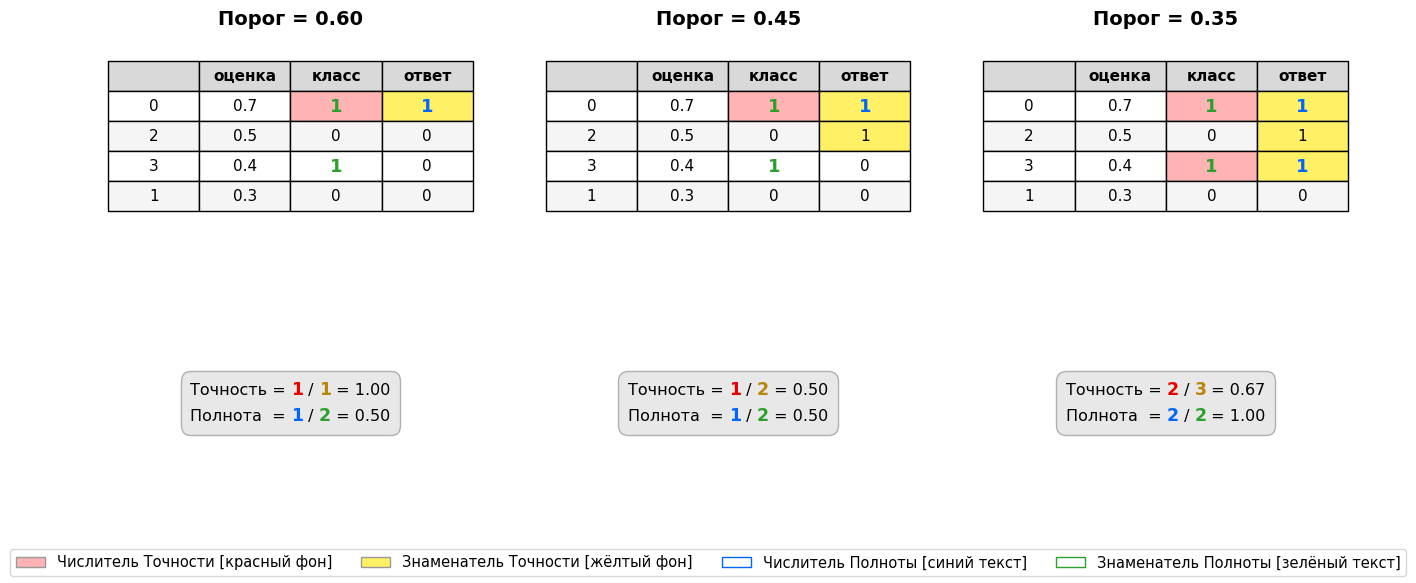

In [28]:
# визуализация расчёта recall и precision

import matplotlib.patches as mpatches
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea, VPacker

data = [
    {"id": 0, "score": 0.7, "y": 1},
    {"id": 2, "score": 0.5, "y": 0},
    {"id": 3, "score": 0.4, "y": 1},
    {"id": 1, "score": 0.3, "y": 0},
]

thresholds = [0.60, 0.45, 0.35]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

C_RED = "#e60000"
C_YELLOW = "#b8860b"
C_BLUE = "#0066ff"
C_GREEN = "#2ca02c"

def make_colored_fraction(
    label, num, den, val, c_num, c_den, font_size=11.5, show_val=True
):
    parts = [
        TextArea(label, textprops=dict(fontsize=font_size, family="sans-serif")),
        TextArea(
            str(num),
            textprops=dict(
                fontsize=font_size + 1,
                color=c_num,
                weight="bold",
                family="sans-serif",
            ),
        ),
        TextArea(
            " / ", textprops=dict(fontsize=font_size, family="sans-serif")
        ),
        TextArea(
            str(den),
            textprops=dict(
                fontsize=font_size + 1,
                color=c_den,
                weight="bold",
                family="sans-serif",
            ),
        ),
    ]
    if show_val:
        parts.append(
            TextArea(
                f" = {val:.2f}",
                textprops=dict(fontsize=font_size, family="sans-serif"),
            )
        )
    return HPacker(children=parts, align="center", pad=0, sep=0)

for ax, t in zip(axes, thresholds):
    ax.axis("off")

    table_rows = []
    statuses = []
    for item in data:
        pred = 1 if item["score"] >= t else 0
        table_rows.append([item["id"], f"{item['score']:.1f}", item["y"], pred])

        if item["y"] == 1 and pred == 1:
            statuses.append("TP")
        elif item["y"] == 0 and pred == 1:
            statuses.append("FP")
        elif item["y"] == 1 and pred == 0:
            statuses.append("FN")
        else:
            statuses.append("TN")

    tp = statuses.count("TP")
    fp = statuses.count("FP")
    fn = statuses.count("FN")
    tn = statuses.count("TN")

    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0

    col_labels = ["", "оценка", "класс", "ответ"]
    tab = ax.table(
        cellText=table_rows,
        colLabels=col_labels,
        cellLoc="center",
        loc="upper center",
    )
    tab.auto_set_font_size(False)
    tab.set_fontsize(11)
    tab.scale(1.0, 1.9)

    for c in range(4):
        tab[(0, c)].set_facecolor("#d9d9d9")
        tab[(0, c)].get_text().set_weight("bold")

    for i, st in enumerate(statuses):
        row_idx = i + 1
        base_bg = "#f5f5f5" if i % 2 == 1 else "#ffffff"
        for c in range(4):
            tab[(row_idx, c)].set_facecolor(base_bg)

        cell_class = tab[(row_idx, 2)]
        cell_pred = tab[(row_idx, 3)]

        if st == "TP":
            cell_class.set_facecolor("#ffb3b3")
            cell_class.get_text().set_color(C_GREEN)
            cell_class.get_text().set_weight("bold")
            cell_class.get_text().set_fontsize(13)

            cell_pred.set_facecolor("#fff066")
            cell_pred.get_text().set_color(C_BLUE)
            cell_pred.get_text().set_weight("bold")
            cell_pred.get_text().set_fontsize(13)

        elif st == "FP":
            cell_pred.set_facecolor("#fff066")

        elif st == "FN":
            cell_class.get_text().set_color(C_GREEN)
            cell_class.get_text().set_weight("bold")
            cell_class.get_text().set_fontsize(13)

    ax.set_title(f"Порог = {t:.2f}", fontsize=14, fontweight="bold", pad=20)

    line_prec = make_colored_fraction(
        "Точность = ", tp, tp + fp, prec, C_RED, C_YELLOW
    )
    line_rec = make_colored_fraction(
        "Полнота  = ", tp, tp + fn, rec, C_BLUE, C_GREEN
    )

    stat_box = VPacker(
        children=[line_prec, line_rec], align="left", pad=0, sep=6
    )

    annot_box = AnnotationBbox(
        stat_box,
        xy=(0.5, 0.20),
        xycoords="axes fraction",
        box_alignment=(0.5, 0.5),
        bboxprops=dict(
            boxstyle="round,pad=0.7", facecolor="#e8e8e8", edgecolor="#b0b0b0"
        ),
    )
    ax.add_artist(annot_box)

legend_elements = [
    mpatches.Patch(
        facecolor="#ffb3b3",
        edgecolor="#999",
        label="Числитель Точности [красный фон]",
    ),
    mpatches.Patch(
        facecolor="#fff066",
        edgecolor="#999",
        label="Знаменатель Точности [жёлтый фон]",
    ),
    mpatches.Patch(
        facecolor="white",
        edgecolor=C_BLUE,
        label="Числитель Полноты [синий текст]",
    ),
    mpatches.Patch(
        facecolor="white",
        edgecolor=C_GREEN,
        label="Знаменатель Полноты [зелёный текст]",
    ),
]
fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=4,
    fontsize=10.5,
    frameon=True,
)

plt.subplots_adjust(bottom=0.15, top=0.88)
plt.show()

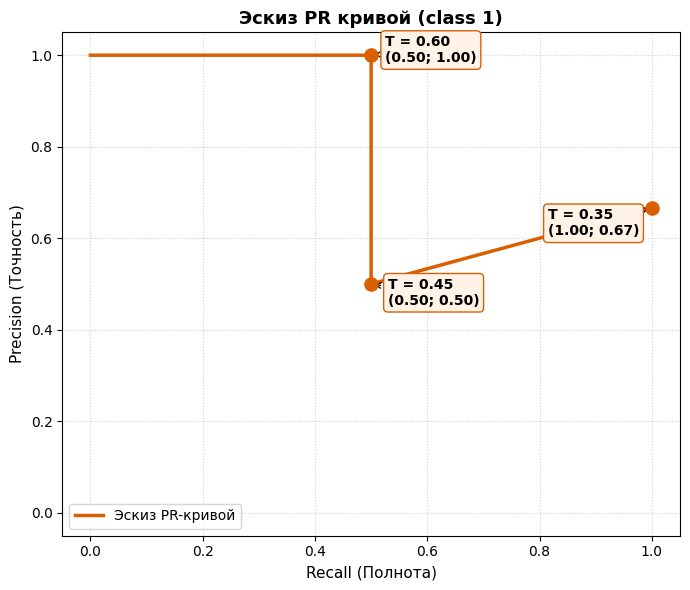

In [16]:
# построение эскиза PR-кривой

recalls = [0.5, 0.5, 1.000]
precisions = [1.000, 0.5, 0.667]
thresholds = [0.60, 0.45, 0.35]

plt.figure(figsize=(7, 6))

sketch_recall = [0.0] + recalls
sketch_prec = [1.0] + precisions

plt.plot(
    sketch_recall,
    sketch_prec,
    color="#d95f02",
    lw=2.5,
    linestyle="-",
    label="Эскиз PR-кривой",
)

plt.scatter(recalls, precisions, color="#d95f02", s=90, zorder=5)

labels = [f"T = {thresholds[i]:.2f}\n({recalls[i]:.2f}; {precisions[i]:.2f})" for i in range(len(recalls))]
offsets = [(10, -5), (12, -15), (-75, -20)]

for r, p, txt, off in zip(recalls, precisions, labels, offsets):
    plt.annotate(
        txt,
        xy=(r, p),
        xytext=off,
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3", facecolor="#fff2e6", edgecolor="#d95f02"
        ),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0"),
    )

plt.title(
    "Эскиз PR кривой (class 1)", fontsize=13, fontweight="bold"
)
plt.xlabel("Recall (Полнота)", fontsize=11)
plt.ylabel("Precision (Точность)", fontsize=11)
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", fontsize=10)

plt.tight_layout()
plt.show()